Скачает через tinkoff-invest-api котировки голубых фишек российских компаний за последний полгода.

Загружаем нужыне бибилотеки.

In [ ]:
pip install ipykernel jupyter yfinance pandas matplotlib

Код загрузки данных:

In [ ]:
import requests
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

# Определяем тикеры (MOEX)
tickers = {
    "LKOH": "ЛУКОЙЛ",
    "GAZP": "Газпром",
    "SBER": "Сбербанк",
    "TATN": "Татнефть",
    "TTLK": "Т-Технологии",
    "NVTK": "НОВАТЭК",
    "GMKN": "Норильский никель",
    "ROSN": "Роснефть",
    "PLZL": "Полюс",
    "SNGS": "Сургутнефтегаз",
    "CHMF": "Северсталь",
    "NLMK": "НЛМК",
    "MOEX": "Московская Биржа",
}

# Устанавливаем даты (за последние 6 месяцев)
end_date = datetime.now()
start_date = end_date - timedelta(days=180)

# Функция для загрузки данных с MOEX ISS (цена + объем)
def get_moex_data(ticker, start_date, end_date):
    url = f"https://iss.moex.com/iss/history/engines/stock/markets/shares/boards/TQBR/securities/{ticker}.json"
    params = {
        "from": start_date.strftime("%Y-%m-%d"),
        "till": end_date.strftime("%Y-%m-%d"),
        "iss.meta": "off"
    }
    response = requests.get(url, params=params)
    data = response.json()
    
    if "history" not in data:
        print(f"Нет данных для {ticker}")
        return None
    
    df = pd.DataFrame(data["history"]["data"], columns=data["history"]["columns"])
    df["TRADEDATE"] = pd.to_datetime(df["TRADEDATE"])
    df.set_index("TRADEDATE", inplace=True)
    return df[["CLOSE", "VOLUME"]]


price_data = pd.DataFrame()
volume_data = pd.DataFrame()

for ticker in tickers:
    try:
        df = get_moex_data(ticker, start_date, end_date)
        if df is not None:
            if price_data.empty:
                price_data = df[["CLOSE"]].rename(columns={"CLOSE": ticker})
                volume_data = df[["VOLUME"]].rename(columns={"VOLUME": ticker})
            else:
                price_data = price_data.join(df[["CLOSE"]].rename(columns={"CLOSE": ticker}), how="outer")
                volume_data = volume_data.join(df[["VOLUME"]].rename(columns={"VOLUME": ticker}), how="outer")
          
        
    except Exception as e:
        print(f"Ошибка при загрузке {ticker}: {str(e)}")

# Сохраняем данные
for ticker in tickers:
    if ticker in price_data.columns:
        # Сохраняем цену и объем в один файл
        combined_df = pd.DataFrame({
            "PRICE": price_data[ticker],
            "VOLUME": volume_data[ticker]
        })
        combined_df.to_csv(f"{ticker}_data.csv")


Напишем фукнцию, которая выполнит сплит для загруженных котировок.

In [ ]:
import pandas as pd
import os

def apply_split_to_all_tickers(ratio, input_dir=".", output_dir="split_adjusted"):
    """
    Применяет коэффициент сплита ко всем файлам с тикерами:
    - цена умножается на ratio
    - объем (или кол-во акций) умножается на 1/ratio
    
    Параметры:
        ratio (float): Коэффициент сплита (напр. 0.5 для сплита 2:1)
        input_dir (str): Папка с исходными файлами
        output_dir (str): Папка для сохранения результатов
    """
    if ratio <= 0:
        raise ValueError("Коэффициент должен быть положительным")
    
    os.makedirs(output_dir, exist_ok=True)
    
    # Ваш список тикеров
    tickers = ["LKOH", "GAZP", "SBER", "TATN", "TTLK", "NVTK", 
               "GMKN", "ROSN", "PLZL", "SNGS", "CHMF", "NLMK", "MOEX"]
    
    for ticker in tickers:
        input_file = os.path.join(input_dir, f"{ticker}_data.csv")
        
        if not os.path.exists(input_file):
            print(f"Файл {input_file} не найден, пропускаем...")
            continue
            
        try:
            df = pd.read_csv(input_file, parse_dates=['TRADEDATE'], index_col='TRADEDATE')
            
            # Определяем есть ли объем или кол-во акций
            if 'VOLUME' in df.columns:
                volume_col = 'VOLUME'
            elif 'SHARES_OUTSTANDING' in df.columns:
                volume_col = 'SHARES_OUTSTANDING'
            else:
                print(f"Нет данных об объеме/акциях для {ticker}")
                continue
            
            # Применяем коэффициенты
            df['PRICE'] = df['PRICE'] * ratio
            df[volume_col] = df[volume_col] * (1 / ratio)
            
            # Сохраняем
            output_file = os.path.join(output_dir, f"{ticker}_split_adjusted.csv")
            df.to_csv(output_file)
            print(f"Обработан {ticker}: цена × {ratio}, {volume_col} × {1/ratio:.2f}")
            
        except Exception as e:
            print(f"Ошибка при обработке {ticker}: {str(e)}")

# Пример использования:
if __name__ == "__main__":
    # Для сплита 2:1
    apply_split_to_all_tickers(ratio=0.5)
    
    # Для сплита 3:2
    # apply_split_to_all_tickers(ratio=2/3)

Построим Mean-Variabre Portfolion

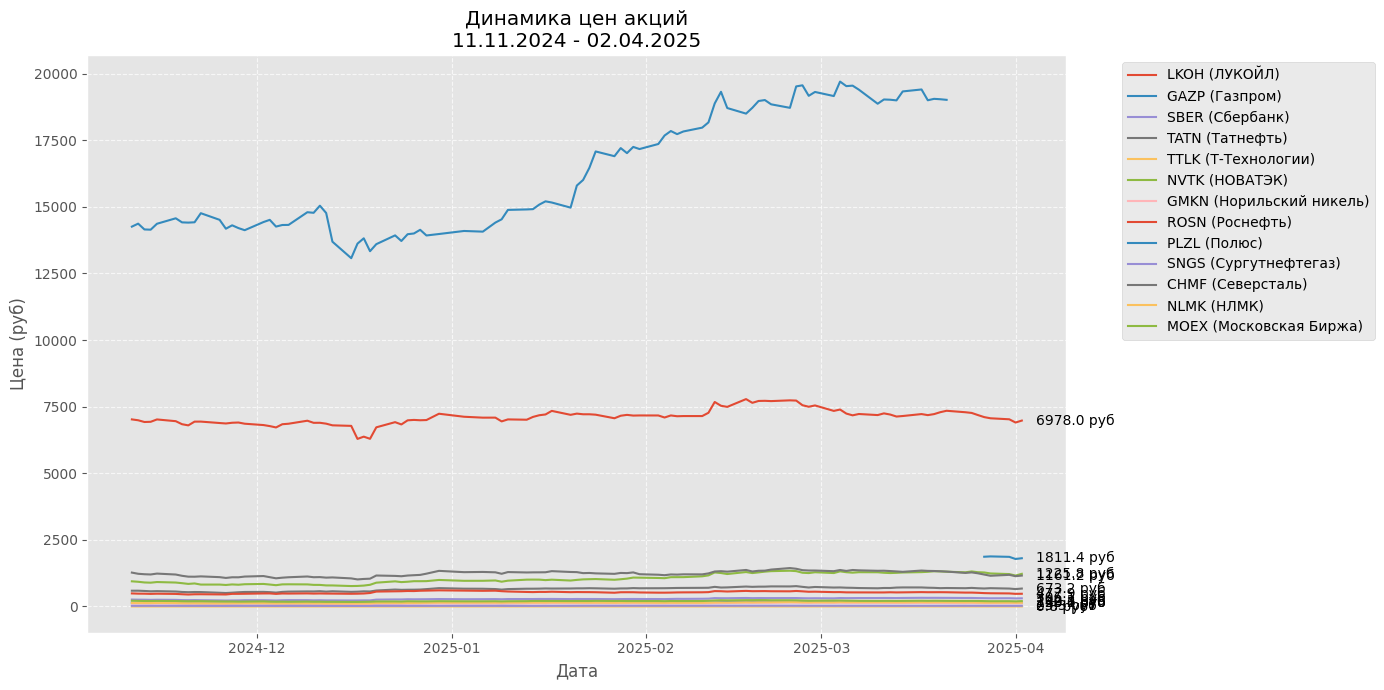

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Настройки графиков
rcParams['figure.figsize'] = (12, 6)
plt.style.use('ggplot')  # Простой встроенный стиль

# Словарь тикеров
tickers = {
    "LKOH": "ЛУКОЙЛ",
    "GAZP": "Газпром",
    "SBER": "Сбербанк",
    "TATN": "Татнефть",
    "TTLK": "Т-Технологии",
    "NVTK": "НОВАТЭК",
    "GMKN": "Норильский никель",
    "ROSN": "Роснефть",
    "PLZL": "Полюс",
    "SNGS": "Сургутнефтегаз",
    "CHMF": "Северсталь",
    "NLMK": "НЛМК",
    "MOEX": "Московская Биржа"
}

def plot_stock_prices(ticker_list=None):
    """
    Строит графики абсолютных цен акций
    
    Параметры:
        ticker_list (list): Список тикеров для отображения (None - все тикеры)
    """
    if ticker_list is None:
        ticker_list = list(tickers.keys())
    
    # Загружаем данные из файлов
    data_frames = []
    valid_tickers = []
    
    for ticker in ticker_list:
        try:
            df = pd.read_csv(f"{ticker}_data.csv", 
                           parse_dates=['TRADEDATE'], 
                           index_col='TRADEDATE')
            if 'PRICE' in df.columns:
                df[ticker] = df['PRICE']  # Используем абсолютные цены
                data_frames.append(df[[ticker]])
                valid_tickers.append(ticker)
        except FileNotFoundError:
            print(f"Файл {ticker}_data.csv не найден, пропускаем...")
    
    if not data_frames:
        print("Нет данных для построения графиков")
        return
    
    # Объединяем данные
    prices_df = pd.concat(data_frames, axis=1)
    
    # Создаем график
    plt.figure(figsize=(14, 7))
    
    for ticker in prices_df.columns:
        plt.plot(prices_df.index, prices_df[ticker], 
                label=f"{ticker} ({tickers.get(ticker, '')})")
    
    # Настройки отображения
    plt.title(f"Динамика цен акций\n"
             f"{prices_df.index[0].strftime('%d.%m.%Y')} - {prices_df.index[-1].strftime('%d.%m.%Y')}")
    plt.ylabel("Цена (руб)")
    plt.xlabel("Дата")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    # Показываем последние значения
    last_values = prices_df.iloc[-1]
    for ticker, value in last_values.items():
        plt.annotate(f"{value:.1f} руб", 
                    xy=(prices_df.index[-1], value),
                    xytext=(10, 0), textcoords='offset points',
                    ha='left', va='center')
    
    plt.show()

# Запуск построения графиков
if __name__ == "__main__":
    plot_stock_prices()  # Для всех акций
   

<Figure size 1000x600 with 0 Axes>

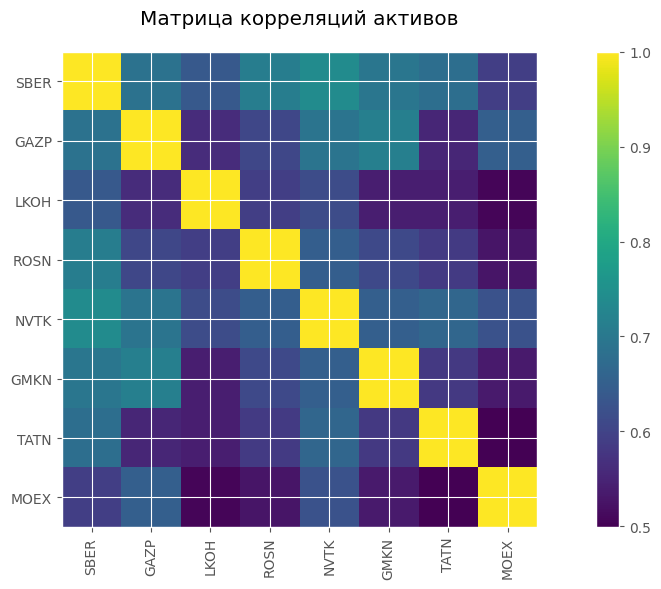

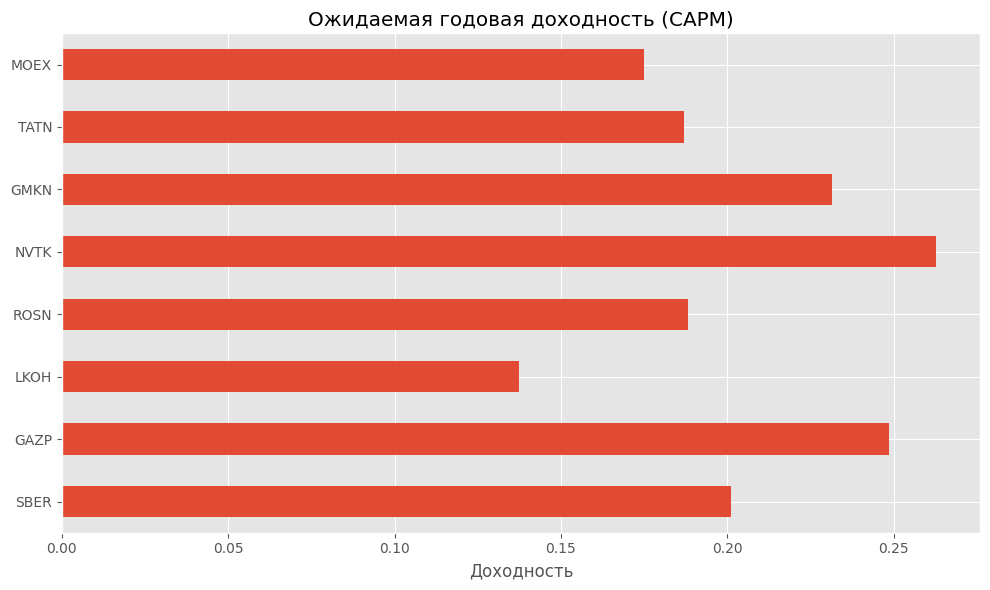


Оптимальное распределение активов:
SBER: 12.6%
GAZP: 13.0%
LKOH: 11.4%
ROSN: 12.5%
NVTK: 13.4%
GMKN: 12.7%
TATN: 12.3%
MOEX: 12.1%

Ожидаемые показатели портфеля:
Expected annual return: 20.6%
Annual volatility: 30.1%
Sharpe Ratio: 0.68

Рекомендации по покупке:
Количество акций:
{'SBER': 411, 'GAZP': 937, 'LKOH': 16, 'ROSN': 261, 'NVTK': 109, 'GMKN': 1063, 'TATN': 184, 'MOEX': 599}
Неиспользованные средства: 1001.42 руб


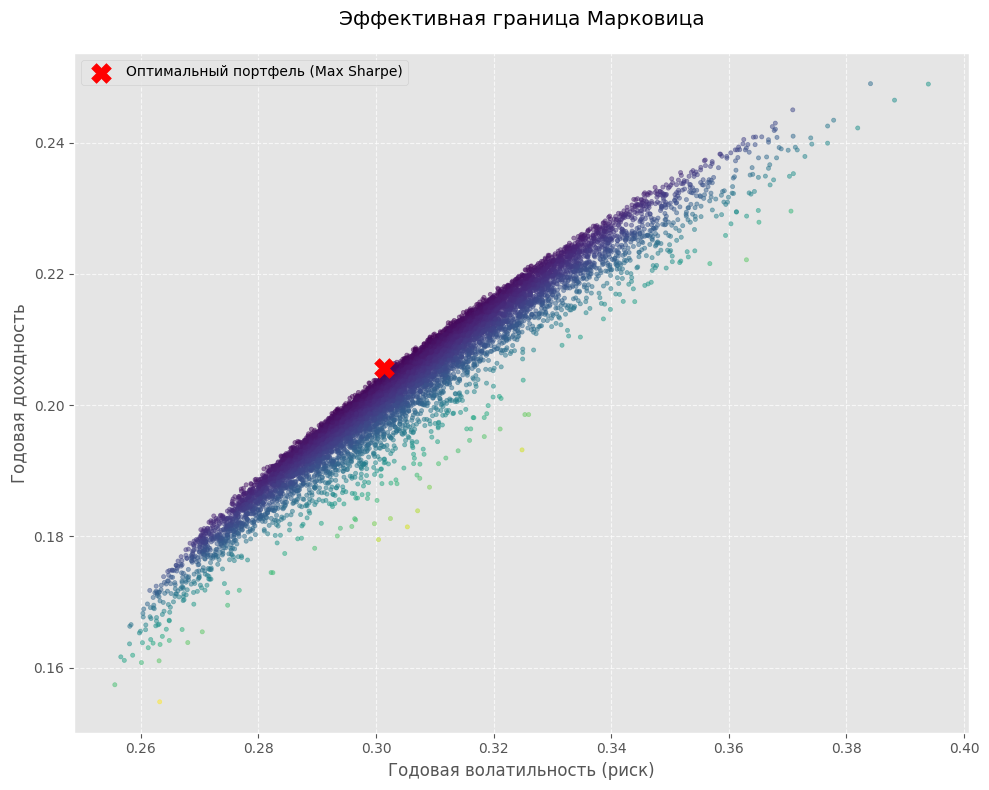

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pypfopt import risk_models, expected_returns, EfficientFrontier, plotting, discrete_allocation

# 1. Загрузка данных
def load_data(tickers):
    """
    Загружает исторические данные из CSV файлов
    Формат файлов: TRADEDATE (дата), PRICE (цена закрытия)
    """
    data = {}
    for ticker in tickers:
        try:
            df = pd.read_csv(f"{ticker}_data.csv", 
                           parse_dates=['TRADEDATE'], 
                           index_col='TRADEDATE')
            data[ticker] = df['PRICE']
        except FileNotFoundError:
            print(f"Файл {ticker}_data.csv не найден, пропускаем...")
    return pd.DataFrame(data)

# 2. Основные параметры
tickers = ["SBER", "GAZP", "LKOH", "ROSN", "NVTK", "GMKN", "TATN", "MOEX"]
portfolio = load_data(tickers)

# 3. Расчет ковариационной матрицы
cov_matrix = risk_models.CovarianceShrinkage(portfolio).ledoit_wolf()

# Визуализация корреляций
plt.figure(figsize=(10, 6))
plotting.plot_covariance(cov_matrix, plot_correlation=True)
plt.title("Матрица корреляций активов", pad=20)
plt.tight_layout()
plt.show()

# 4. Расчет ожидаемой доходности
mu = expected_returns.capm_return(portfolio)

# График доходностей
mu.plot.barh(figsize=(10,6))
plt.title("Ожидаемая годовая доходность (CAPM)")
plt.xlabel("Доходность")
plt.tight_layout()
plt.show()

# 5. Оптимизация портфеля
ef = EfficientFrontier(mu, cov_matrix)
weights = ef.max_sharpe()
cleaned_weights = ef.clean_weights()

print("\nОптимальное распределение активов:")
for ticker, weight in cleaned_weights.items():
    if weight > 0.01:  # Показываем только значимые веса
        print(f"{ticker}: {weight*100:.1f}%")

# Оценка эффективности
print("\nОжидаемые показатели портфеля:")
ef.portfolio_performance(verbose=True)

# 6. Практическая реализация
latest_prices = discrete_allocation.get_latest_prices(portfolio)
allocation = discrete_allocation.DiscreteAllocation(
    cleaned_weights,
    latest_prices,
    total_portfolio_value=1000000  # Бюджет 1 млн руб
)

alloc, leftover = allocation.lp_portfolio()

print("\nРекомендации по покупке:")
print("Количество акций:")
print(alloc)
print(f"Неиспользованные средства: {leftover:.2f} руб")

# 7. Визуализация эффективной границы
fig, ax = plt.subplots(figsize=(10, 8))

# Генерация случайных портфелей
n_portfolios = 10000
w = np.random.dirichlet(np.ones(len(mu)), n_portfolios)
rets = w.dot(mu)
stds = np.sqrt(np.diag(w @ cov_matrix @ w.T))
sharpe = rets / stds

# Оптимальный портфель
ef = EfficientFrontier(mu, cov_matrix)
ef.max_sharpe()
ret_opt, risk_opt, _ = ef.portfolio_performance()

# Построение графиков
ax.scatter(stds, rets, marker='.', c=sharpe, cmap='viridis_r', alpha=0.5)
ax.scatter(risk_opt, ret_opt, marker='X', s=200, c='red', label='Оптимальный портфель (Max Sharpe)')

ax.set_title("Эффективная граница Марковица", pad=20)
ax.set_xlabel("Годовая волатильность (риск)")
ax.set_ylabel("Годовая доходность")
ax.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()